In [6]:
#LOAD DATA
import pandas as pd
file_path = r"C:\Users\papan\Desktop\Coffeeomics\Coffeeomics.xlsx"
metabolomics = pd.read_excel(file_path, sheet_name="Metab_Counts", index_col=0, header=[0, 1, 2, 3, 4])

In [ ]:
metabolomics
metabolomics.to_csv(
    r"C:\Users\papan\Desktop\Coffeeomics\metabolomics\data\metabolomics_counts.csv",
    index=True
)

In [10]:
metabolomics.head()

C. arabica                                                    \
                   25                                                     
               380ppm                                                     
              without                                  medium             
                   7B        7C        7D        7E       20B       20C   
Alanine      0.095671  0.079418  0.083702  0.235326  0.079602  0.041641   
Pyruvate     0.002447  0.002580  0.004289  0.004251  0.002082  0.000000   
Valine       0.017711  0.006620  0.014389  0.014561  0.008683  0.006364   
Glycerol     0.002649  0.003916  0.002642  0.002065  0.002437  0.002140   
Isoleucine   0.005574  0.003709  0.007076  0.005104  0.011942  0.006009   

                                                    ... C. canephora  \
                                                    ...      RECOVER   
                                                    ...       700ppm   
                        severe                      ...      without   
                  8A       21D        9A        9B  ...          52A   
Alanine     0.125572  0.109679  0.183377  0.077657  ...     0.153630   
Pyruvate    0.001596  0.000000  0.003251  0.001274  ...     0.005233   
Valine      0.025072  0.056592  0.057696  0.077255  ...     0.039423   
Glycerol    0.003148  0.001765  0.003320  0.004516  ...     0.002493   
Isoleucine  0.013022  0.026935  0.040210  0.035172  ...     0.015661   

                                                                        \
                                                                         
                                                                         
                                                      severe             
                 52B       52C       52D       52E       54A       54B   
Alanine     0.190585  0.233703  0.231378  0.000000  0.157784  0.297664   
Pyruvate    0.002289  0.006579  0.008194  0.000000  0.004737  0.004070   
Valine      0.031041  0.033949  0.019111  0.000000  0.014898  0.013307   
Glycerol    0.002340  0.004168  0.003137  0.000000  0.003910  0.002910   
Isoleucine  0.011012  0.012747  0.007077  0.004775  0.005673  0.003363   

                                          
                                          
                                          
                                          
                 54C       54D       54E  
Alanine     0.164530  0.377928  0.198444  
Pyruvate    0.002894  0.005966  0.003501  
Valine      0.033017  0.032359  0.018622  
Glycerol    0.003682  0.005176  0.002212  
Isoleucine  0.010131  0.013444  0.003920  

[5 rows x 156 columns]

In [2]:
total = metabolomics.size

num_zeros = (metabolomics == 0).sum().sum()
num_ones = (metabolomics == 1).sum().sum()
num_nan = metabolomics.isna().sum().sum()

print(f"Number of 0s: {num_zeros}/{total} ({num_zeros/total*100:.2f}%)")
print(f"Number of 1s: {num_ones}/{total} ({num_ones/total*100:.2f}%)")
print(f"Number of NaNs: {num_nan}/{total} ({num_nan/total*100:.2f}%)")

Number of 0s: 929/7800 (11.91%)
Number of 1s: 0/7800 (0.00%)
Number of NaNs: 0/7800 (0.00%)


In [3]:
numeric_data = metabolomics.select_dtypes(include='number')

overall_min = numeric_data.min().min()
overall_max = numeric_data.max().max()
print(f"Range of values: {overall_min} to {overall_max}")
print(f"{len(metabolomics)} metabolites: {list(metabolomics.index)}")

Range of values: 0.0 to 4.185098795186635
50 metabolites: ['Alanine', 'Pyruvate', 'Valine', 'Glycerol', 'Isoleucine', 'Glycine', 'Phosphoric acid', 'Proline', 'Glycerate', 'Serine', 'Succinate', 'Threonine', 'Fumarate', 'Nicotinic acid', 'beta-Alanine', 'Erythritol', 'Malate', 'GABA', 'Aspartate', 'Threonate', 'Methionine', 'Ornithine', 'Pyroglutamate', 'Glutamate', 'Rhamnose', 'Putrescine', '2-Oxoglutarate', 'Fucose', 'Phenylalanine', 'Asparagine', 'Glycerol-3-phosphate', 'Citrate', 'Arginine', 'Lysine', 'Dehydroascorbate', 'Tyramine', 'myo-Inositol', 'Tyrosine', 'Histidine', 'Glucose-6-phosphate', 'Tryptophan', 'Cystine', 'Trehalose', 'Spermine', 'Galactinol', 'Raffinose', 'Quinate', 'Fructose', 'Glucose', 'Sucrose']


Number of values: 7800
count    7800.000000
mean        0.120786
std         0.282284
min         0.000000
25%         0.002374
50%         0.019794
75%         0.115405
max         4.185099
dtype: float64


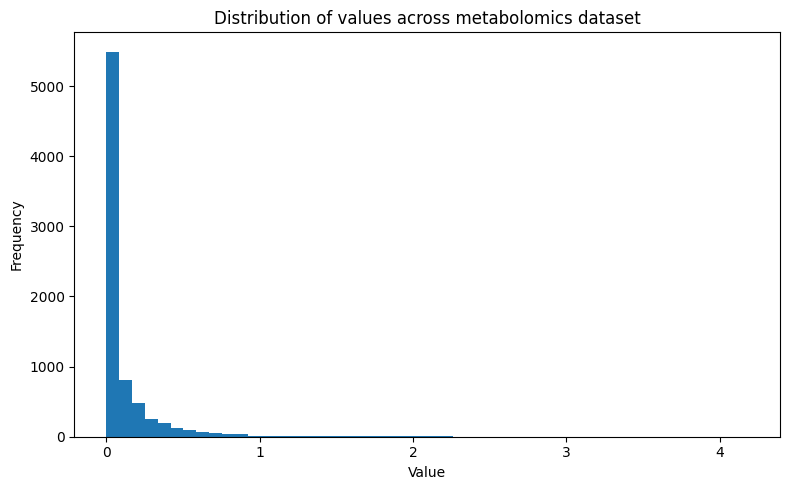

In [4]:
import matplotlib.pyplot as plt

numeric_data = metabolomics.select_dtypes(include='number')

# Flatten ALL values into a single 1D array, regardless of MultiIndex columns
all_values = numeric_data.to_numpy().flatten()
all_values = all_values[~pd.isna(all_values)]  # drop NaNs

print(f"Number of values: {len(all_values)}")
print(pd.Series(all_values).describe())

# Histogram of the full distribution
plt.figure(figsize=(8, 5))
plt.hist(all_values, bins=50)
plt.xlabel("Value")
plt.ylabel("Frequency")
plt.title("Distribution of values across metabolomics dataset")
plt.tight_layout()
plt.show()

In [4]:
import json
from pathlib import Path

output_path = Path(r"C:\Users\papan\Desktop\Coffeeomics\metabolomics_index.json")
with open(output_path, "w", encoding="utf-8") as f:
    json.dump(list(metabolomics.index), f, indent=2, ensure_ascii=False)

PCA

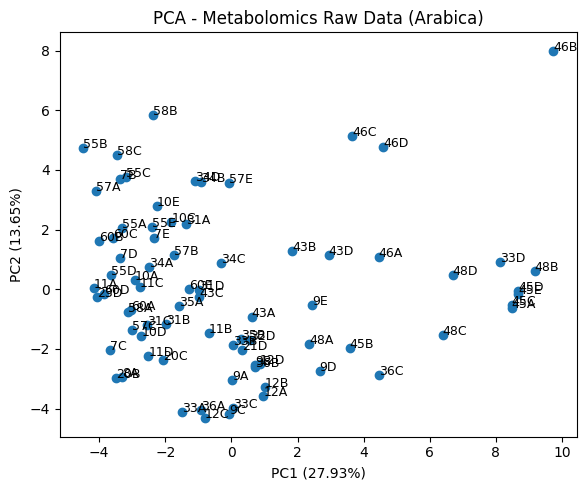

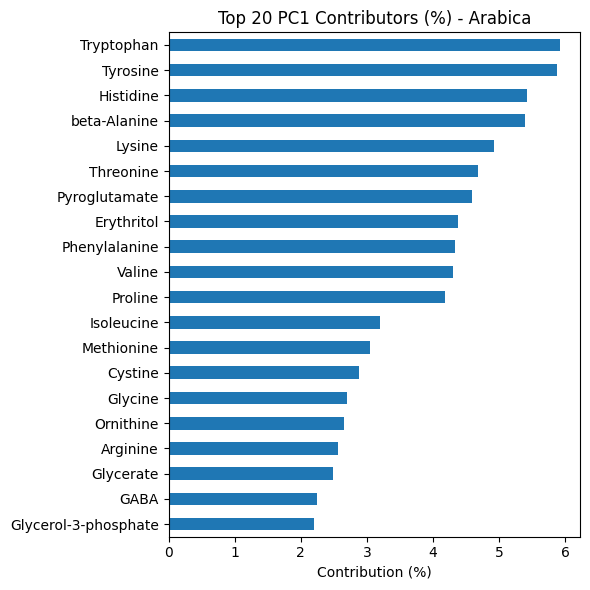

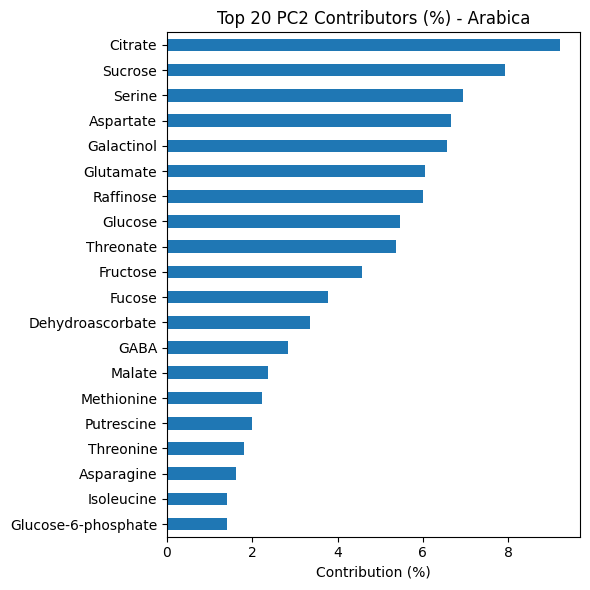

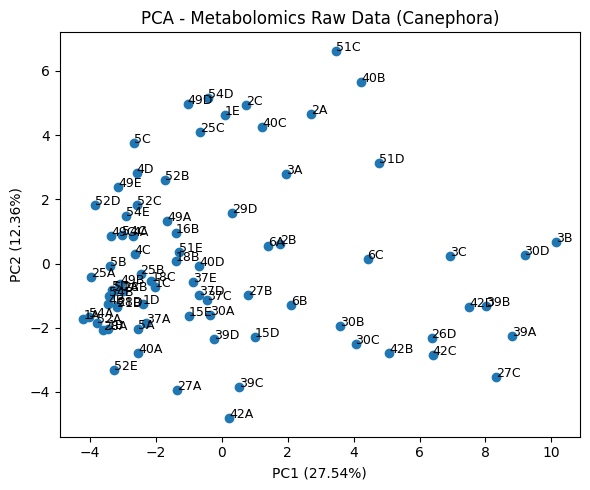

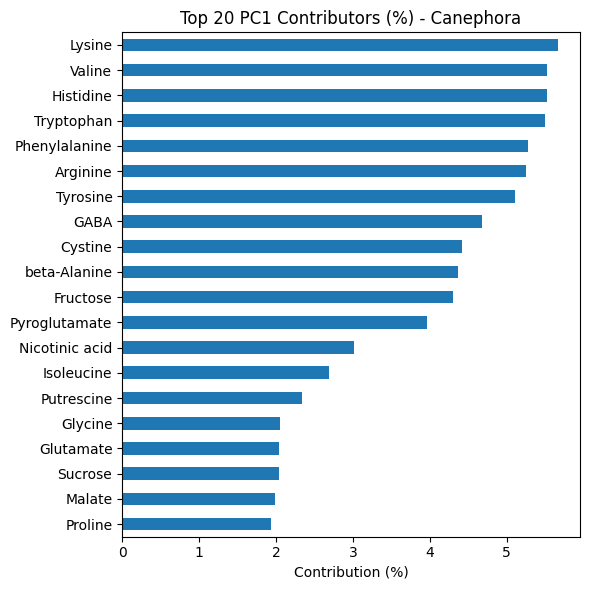

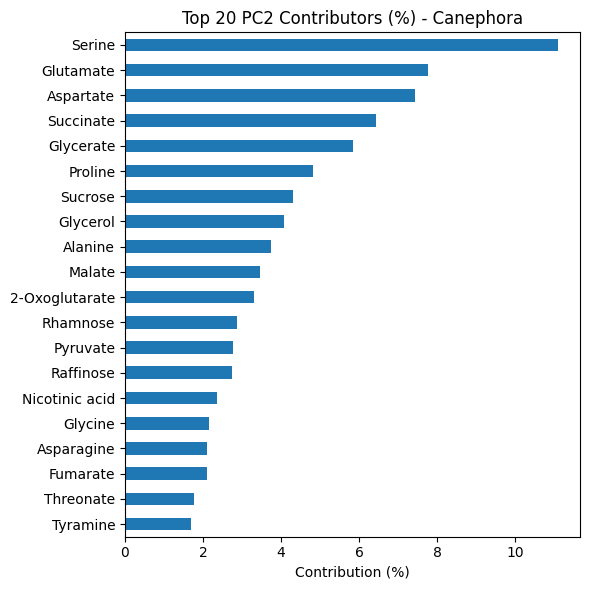

In [6]:
import sys
sys.path.append(r"C:\Users\papan\Desktop\Coffeeomics")
from pca import run_pca_analysis

arabica_ids = metabolomics.columns[metabolomics.columns.get_level_values(0) == "C. arabica"]
canephora_ids = metabolomics.columns[metabolomics.columns.get_level_values(0) == "C. canephora"]

run_pca_analysis(metabolomics, arabica_ids=arabica_ids, canephora_ids=canephora_ids, name="Metabolomics Raw Data", top=20, log_transform=True)